### Carga y variables iniciales

In [2]:
import numpy as np
import pandas as pd
import warnings
from IPython.display import display
import matplotlib.pyplot as plt 
import matplotlib.colors as mcolors
import seaborn as sns

sns.set_theme(style='darkgrid', palette='pastel')
sns.set_style('ticks') # Use a Seaborn style (e.g., 'ticks') for other aesthetics
plt.style.use('dark_background')

warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=DeprecationWarning)

In [3]:
# INIT variables
f1_EDA = pd.read_csv('F1_cleaned.csv')
year_start = 2021
max_year = f1_EDA["year"].max()

hbox_subplots_year = (max_year - year_start + 1) // 2

## Análisis de Outliers

In [4]:
def boxplot_and_histplot(data, title_):
    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    sns.boxplot(data, color='#F7D31D')
    plt.axhline(data.mean(), color='r', linestyle='--', label='Mean')
    plt.axhline(data.median(), color='b', linestyle='-.', label='Median')
    plt.legend()
    plt.title(title_)

    plt.subplot(1, 2, 2)
    plt.axvline(data.mean(), color='r', linestyle='--', label='Mean')
    plt.axvline(data.median(), color='b', linestyle='-.', label='Median')
    plt.legend()
    sns.histplot(data, kde=True, color='#F7D31D', bins=30)
    plt.title(title_)
    plt.tight_layout()
    plt.show()    

### Variables del Lap más rápido

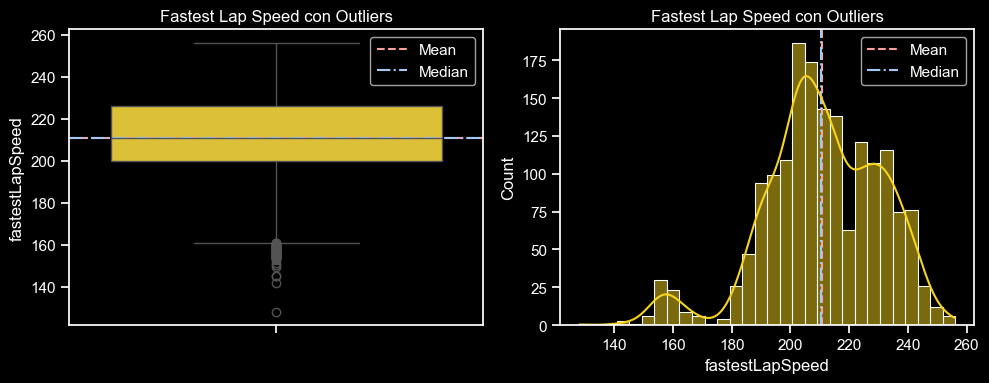

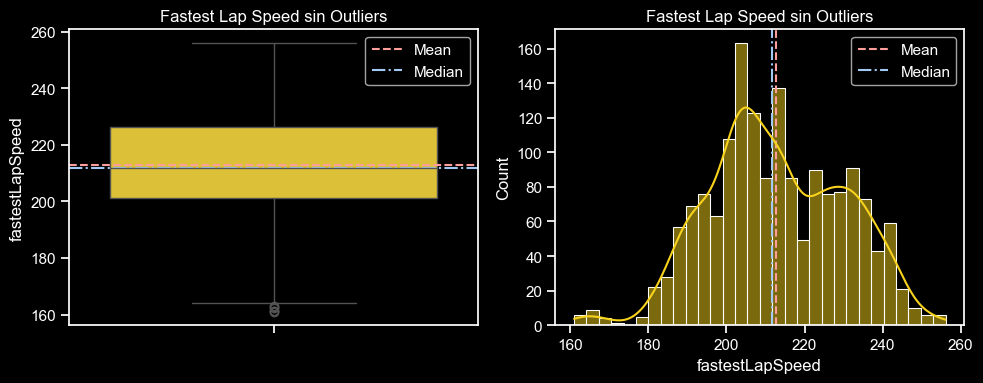

In [5]:
# quitemos los 'fastestLapSpeed' con in_sprint == 1 para evitar los ceros
sel_fastestLapSpeed = f1_EDA.where(f1_EDA['in_sprint'] == 0).where(f1_EDA['fastestLapSpeed'] != 0)['fastestLapSpeed']

Q1 = sel_fastestLapSpeed.quantile(0.25)
Q3 = sel_fastestLapSpeed.quantile(0.75)
IQR = Q3 - Q1

# CON OUTLIERS
boxplot_and_histplot(sel_fastestLapSpeed, 'Fastest Lap Speed con Outliers')

sel_fastestLapSpeed_no_outliers = sel_fastestLapSpeed[
    (sel_fastestLapSpeed >= Q1 - 1.5 * IQR) & (sel_fastestLapSpeed <= Q3 + 1.5 * IQR)
]

# SIN OUTLIERS (mediante +- 1.5*IQR
boxplot_and_histplot(sel_fastestLapSpeed_no_outliers, 'Fastest Lap Speed sin Outliers')

No hay diferencia significativa en la media y mediana al quitar los outliers, lo cual concluye que entre 200 y 250 aproximadamente se encuentra la velocidad de los mejores lap de los pilotos en todas las Races.

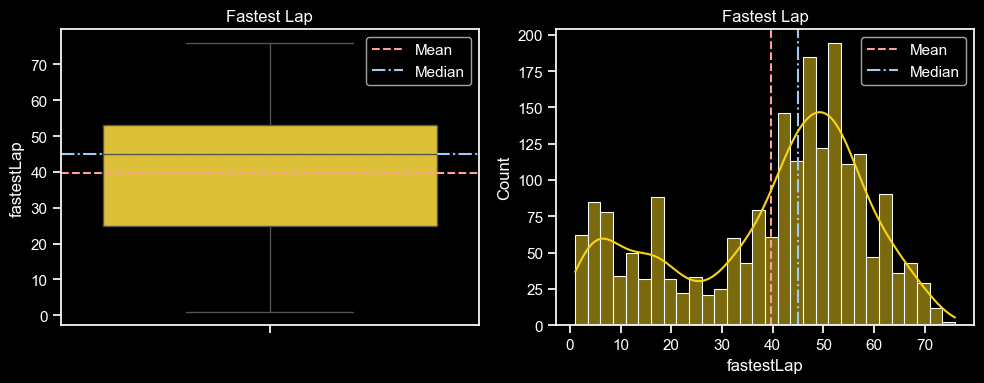

In [6]:
sel_fastestLap = f1_EDA[f1_EDA['fastestLap'] != 0]['fastestLap']

boxplot_and_histplot(sel_fastestLap, 'Fastest Lap')

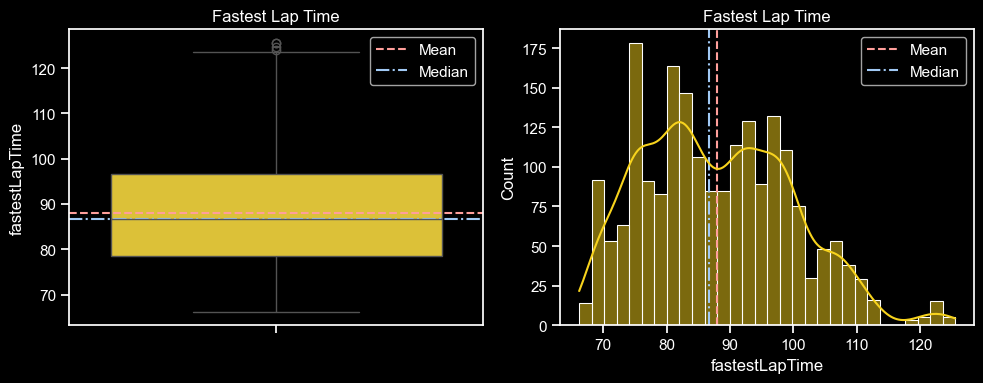

In [7]:
sel_fastestLapTime = f1_EDA[f1_EDA['fastestLapTime'] != 0]['fastestLapTime']

boxplot_and_histplot(sel_fastestLapTime, 'Fastest Lap Time')

Como no hay outliers, el hallazgo de los laps y sus tiempos son independientes, aunque hay un ligero sesgo contrario al orden de la moda con la mediana.

### Tiempos de carreras

In [8]:
finished_race = f1_EDA[f1_EDA['gp_time_mins'] != 0]
finished_race['status'].unique().tolist()

['Finished', 'Retired', 'Disqualified']

Verificando por el `status`, el dataset muestra los tiempos de GP (`race_seconds`) para los resultados cuando ha finalizado los laps con y sin descalificación.

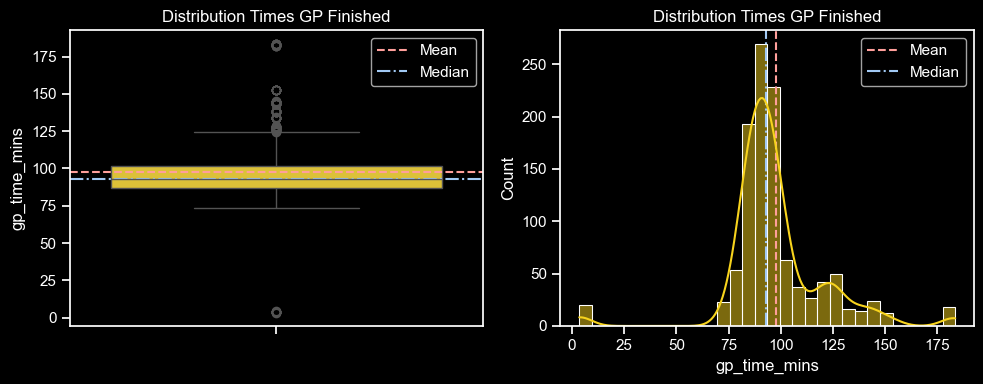

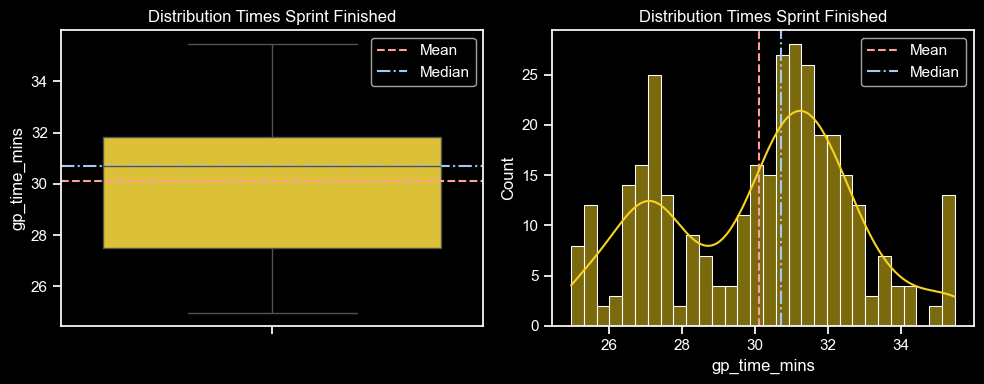

In [9]:
finished_race_gp = finished_race[finished_race['in_sprint'] == 0]
finished_race_sprint = finished_race[finished_race['in_sprint'] == 1]

boxplot_and_histplot(finished_race_gp['gp_time_mins'], 'Distribution Times GP Finished')
boxplot_and_histplot(finished_race_sprint['gp_time_mins'], 'Distribution Times Sprint Finished')

Veamos los outliers dentro de las races Grand Prix

In [10]:
Q1 = finished_race_gp['gp_time_mins'].quantile(0.25)
Q3 = finished_race_gp['gp_time_mins'].quantile(0.75)
IQR = Q3 - Q1
finished_race_gp_down_outliers = finished_race_gp[
    (finished_race_gp['gp_time_mins'] < Q1 - 1.5 * IQR)
]

finished_race_gp_up_outliers = finished_race_gp[
    (finished_race_gp['gp_time_mins'] > Q3 + 1.5 * IQR)
]
print(f'Carreras con standings anómalamente bajos:')
display(
    finished_race_gp_down_outliers.groupby(['circuit_name', 'year']).size() \
    .reset_index(name='n_races').sort_values(by='n_races', ascending=False)
)

print(f'Carreras con standings anómalamente altos:')
display(
     finished_race_gp_up_outliers.groupby(['circuit_name', 'year']).size() \
    .reset_index(name='n_races').sort_values(by='n_races', ascending=False)
)   

Carreras con standings anómalamente bajos:


,circuit_name,year,n_races
0,Circuit de Spa-Francorchamps,2021,20


Carreras con standings anómalamente altos:


,circuit_name,year,n_races
8,Suzuka Circuit,2022,18
3,Circuit Park Zandvoort,2023,17
2,Baku City Circuit,2021,16
1,Autódromo José Carlos Pace,2024,15
7,Silverstone Circuit,2022,14
0,Albert Park Grand Prix Circuit,2023,12
6,Jeddah Corniche Circuit,2021,12
5,Hungaroring,2021,9
4,Circuit de Monaco,2024,7


## Métricas de performance

### Puntajes y posiciones

In [11]:
key_mapper = ['driverId', 'constructorId', 'year']

# solo metricas para Grand Prix
f1_EDA_only_gp = f1_EDA[f1_EDA["in_sprint"] == 0]

init_metrics = f1_EDA_only_gp.groupby(key_mapper).agg({
    'pilot_points': ['sum', 'mean'],
    'driver_name': 'count',
    'grid_position': 'mean',
    'laps': 'sum'
}).round(3)
init_metrics.columns = ['total_pilot_points', 'avg_pilot_points', 'participations', 'avg_grid_position', 'total_laps']

wins = f1_EDA_only_gp[f1_EDA_only_gp['final_position'] == 1].groupby(key_mapper).size().reset_index(name='wins')
podiums = f1_EDA_only_gp[f1_EDA_only_gp['final_position'] <= 3].groupby(key_mapper).size().reset_index(name='podiums')
top10s = f1_EDA_only_gp[f1_EDA_only_gp['final_position'] <= 10].groupby(key_mapper).size().reset_index(name='top10s')

average_final_pos = f1_EDA_only_gp.groupby(key_mapper)['final_position'].mean().round(2).reset_index(name='avg_final_position')
info_pilot_const = f1_EDA_only_gp[key_mapper + ['driver_name', 'constructor_name']].drop_duplicates()

metrics = init_metrics.merge(average_final_pos, on=key_mapper, how='left')
metrics = metrics.merge(wins, on=key_mapper, how='left')
metrics = metrics.merge(podiums, on=key_mapper, how='left')
metrics = metrics.merge(top10s, on=key_mapper, how='left')
metrics[['wins', 'podiums', 'top10s']] = metrics[['wins', 'podiums', 'top10s']].fillna(0)
metrics = metrics.merge(info_pilot_const, on=key_mapper, how='left')

metrics.head(5)

,driverId,constructorId,year,total_pilot_points,avg_pilot_points,participations,avg_grid_position,total_laps,avg_final_position,wins,podiums,top10s,driver_name,constructor_name
0,1,131,2021,385.5,17.523,22,3.091,1269,3.41,8.0,17.0,20.0,Lewis Hamilton,Mercedes
1,1,131,2022,233.0,10.591,22,6.500,1246,6.05,0.0,9.0,19.0,Lewis Hamilton,Mercedes
2,1,131,2023,217.0,9.864,22,6.091,1268,6.18,0.0,6.0,20.0,Lewis Hamilton,Mercedes
3,1,131,2024,207.0,8.625,24,8.042,1346,6.96,2.0,5.0,21.0,Lewis Hamilton,Mercedes
4,4,117,2023,198.0,9.000,22,6.045,1294,6.64,0.0,8.0,19.0,Fernando Alonso,Aston Martin


In [12]:
metrics['points_per_race'] = (metrics['total_pilot_points'] / metrics['participations']).round(2)
metrics['win_rate'] = (metrics['wins'] / metrics['participations'] * 100).round(2)
metrics['podium_rate'] = (metrics['podiums'] / metrics['participations'] * 100).round(2)
metrics['top10_rate'] = (metrics['top10s'] / metrics['participations'] * 100).round(2)

# Ganancia de posicion desde el inicio hasta el final
position_gains = []
for k, group in f1_EDA.groupby(key_mapper):
    valid_races = group.dropna(subset=['grid_position', 'final_position'])
    if len(valid_races) > 0:
        avg_gain = (valid_races['grid_position'] - valid_races['final_position']).mean()
    else:
        avg_gain = 0
    position_gains.append({
        'driverId': k[0], 'constructorId': k[1], 'year': k[2],
        'avg_position_gain': round(avg_gain, 2)
    })
position_gains_df = pd.DataFrame(position_gains)

added_metrics = metrics.merge(position_gains_df, on=key_mapper, how='left')
added_metrics.head(5)

,driverId,constructorId,year,total_pilot_points,avg_pilot_points,participations,avg_grid_position,total_laps,avg_final_position,wins,podiums,top10s,driver_name,constructor_name,points_per_race,win_rate,podium_rate,top10_rate,avg_position_gain
0,1,131,2021,385.5,17.523,22,3.091,1269,3.41,8.0,17.0,20.0,Lewis Hamilton,Mercedes,17.52,36.36,77.27,90.91,0.16
1,1,131,2022,233.0,10.591,22,6.500,1246,6.05,0.0,9.0,19.0,Lewis Hamilton,Mercedes,10.59,0.00,40.91,86.36,0.60
2,1,131,2023,217.0,9.864,22,6.091,1268,6.18,0.0,6.0,20.0,Lewis Hamilton,Mercedes,9.86,0.00,27.27,90.91,0.39
3,1,131,2024,207.0,8.625,24,8.042,1346,6.96,2.0,5.0,21.0,Lewis Hamilton,Mercedes,8.62,8.33,20.83,87.50,0.80
4,4,117,2023,198.0,9.000,22,6.045,1294,6.64,0.0,8.0,19.0,Fernando Alonso,Aston Martin,9.00,0.00,36.36,86.36,-0.39


### Clasificación, consistencia y progresión de puntos

In [13]:
# Qualifying metrics
qual_metrics = f1_EDA_only_gp.groupby(key_mapper).agg({
    'qual_position': ['mean', 'min', 'max', 'count']
}).round(3)
qual_metrics.columns = ['avg_qualifying', 'best_qualifying', 'worst_qualifying', 'qualifying_count']
qual_metrics = qual_metrics.reset_index()

In [14]:
qual_metrics.sample(5)

,driverId,constructorId,year,avg_qualifying,best_qualifying,worst_qualifying,qualifying_count
1,1,131,2022,6.409,3.0,16.0,22
78,856,3,2022,13.000,13.0,13.0,1
77,855,51,2023,15.909,5.0,20.0,22
32,830,9,2023,3.000,1.0,15.0,22
67,849,3,2022,18.591,10.0,20.0,22


In [15]:
# Lap and pit Stop times
lap_times = pd.read_csv("lap_stops_gp.csv")

# Medidas representativas de un piloto por carrera
lap_consistency = lap_times.groupby(["driverId", "raceId"]).agg({
    'duration_lap_mins': ['mean', 'std']
})
# Promedio de esas medidas en pilotos al año
lap_consistency.columns = ["avg_lap_time", "std_lap_time"]
lap_consistency = lap_consistency.reset_index()
consistency_metrics = lap_consistency.groupby('driverId').agg({
    'avg_lap_time': 'mean',
    'std_lap_time': 'mean'
}).round(3)

consistency_metrics['consistency_score'] = \
    (100 - (consistency_metrics['std_lap_time'] / consistency_metrics['avg_lap_time'] * 1000)).round(2)

In [16]:
consistency_metrics.sample(5)

,avg_lap_time,std_lap_time,consistency_score
driverId,,,
839,1.680,0.674,-301.19
855,1.686,0.610,-261.80
807,1.637,0.542,-231.09
822,1.706,0.770,-351.35
817,1.683,0.740,-339.69


In [17]:
added2_metrics = added_metrics.merge(qual_metrics, on=key_mapper, how='left')
added2_metrics = added2_metrics.merge(consistency_metrics, on='driverId', how='left')

added2_metrics.head(5)

,driverId,constructorId,year,total_pilot_points,avg_pilot_points,participations,avg_grid_position,total_laps,avg_final_position,wins,...,podium_rate,top10_rate,avg_position_gain,avg_qualifying,best_qualifying,worst_qualifying,qualifying_count,avg_lap_time,std_lap_time,consistency_score
0,1,131,2021,385.5,17.523,22,3.091,1269,3.41,8.0,...,77.27,90.91,0.16,2.136,1.0,7.0,22,1.660,0.79,-375.90
1,1,131,2022,233.0,10.591,22,6.500,1246,6.05,0.0,...,40.91,86.36,0.60,6.409,3.0,16.0,22,1.660,0.79,-375.90
2,1,131,2023,217.0,9.864,22,6.091,1268,6.18,0.0,...,27.27,90.91,0.39,6.364,1.0,13.0,22,1.660,0.79,-375.90
3,1,131,2024,207.0,8.625,24,8.042,1346,6.96,2.0,...,20.83,87.50,0.80,8.500,2.0,19.0,24,1.660,0.79,-375.90
4,4,117,2023,198.0,9.000,22,6.045,1294,6.64,0.0,...,36.36,86.36,-0.39,7.000,2.0,17.0,22,1.688,0.78,-362.09


### Performance por Season

In [18]:
def calc_performance(row: pd.Series):
    points_score = min(row["points_per_race"] * 5, 100)         
    consistency_score = max(0, row['consistency_score'], 100)
    qualifying_score = max(0, (20 - row['avg_qualifying']) * 5)
    position_gain_score = max(0, min(row["avg_position_gain"] * 10 + 50, 100))
    podium_score = min(row['podium_rate'] * 2, 100)
    top10_score = min(row['top10_rate'] * 2, 100)
    weights = {
        'points': 0.25,
        'consistency': 0.20,
        'qualifying': 0.15,
        'position_gain': 0.15,
        'podium': 0.15,
        'top10': 0.10
    }
    performance_index = (
        points_score * weights['points'] +
        consistency_score * weights['consistency'] +
        qualifying_score * weights['qualifying'] +
        position_gain_score * weights['position_gain'] +
        podium_score * weights['podium'] +
        top10_score * weights['top10']
    )
    return round(performance_index, 2)

In [19]:
added2_metrics["performance_idx"] = added2_metrics.apply(calc_performance, axis=1)
final_metrics = added2_metrics.sort_values('performance_idx', ascending=False)
final_metrics.head(10)

,driverId,constructorId,year,total_pilot_points,avg_pilot_points,participations,avg_grid_position,total_laps,avg_final_position,wins,...,top10_rate,avg_position_gain,avg_qualifying,best_qualifying,worst_qualifying,qualifying_count,avg_lap_time,std_lap_time,consistency_score,performance_idx
32,830,9,2023,530.0,24.091,22,3.182,1325,1.27,19.0,...,100.00,1.57,3.000,1.0,15.0,22,1.641,0.684,-316.82,92.61
31,830,9,2022,433.0,19.682,22,3.409,1271,3.50,15.0,...,90.91,-0.16,2.591,1.0,10.0,22,1.641,0.684,-316.82,89.92
0,1,131,2021,385.5,17.523,22,3.091,1269,3.41,8.0,...,90.91,0.16,2.136,1.0,7.0,22,1.660,0.790,-375.90,88.04
33,830,9,2024,399.0,16.625,24,3.542,1389,3.62,9.0,...,95.83,-0.03,2.917,1.0,12.0,24,1.641,0.684,-316.82,86.04
30,830,9,2021,388.5,17.659,22,2.864,1211,4.14,10.0,...,86.36,-1.08,2.818,1.0,20.0,22,1.641,0.684,-316.82,85.84
54,844,6,2024,327.0,13.625,24,5.417,1413,4.54,3.0,...,87.50,0.87,5.333,1.0,14.0,24,1.651,0.631,-282.19,81.83
58,846,1,2024,344.0,14.333,24,3.375,1437,4.29,4.0,...,95.83,-1.27,3.542,1.0,16.0,24,1.684,0.740,-339.43,80.85
16,815,9,2022,291.0,13.227,22,4.818,1183,5.41,2.0,...,86.36,0.12,5.000,1.0,13.0,22,1.713,0.826,-382.19,80.47
52,844,6,2022,291.0,13.227,22,3.909,1189,5.50,3.0,...,86.36,-1.24,3.000,1.0,15.0,22,1.651,0.631,-282.19,79.93
26,822,131,2021,219.0,9.955,22,5.591,1134,7.41,1.0,...,68.18,-1.56,3.773,1.0,10.0,22,1.706,0.770,-351.35,74.77


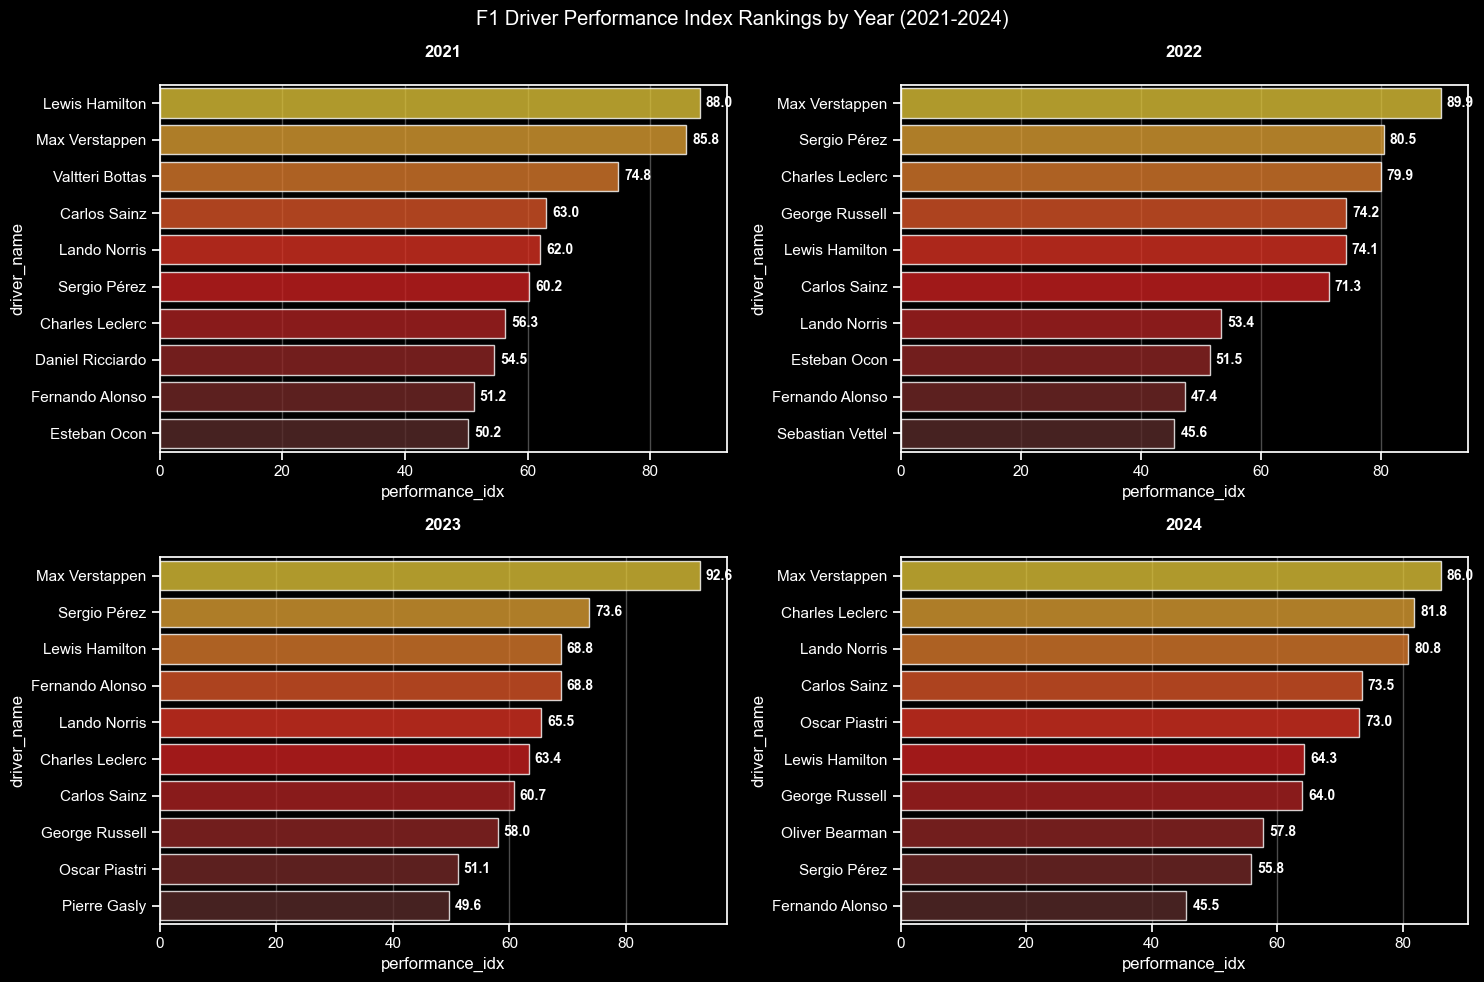

In [20]:
F1_bar_colors = ['#F7D31D', '#F60000', '#5F2423']

plt.figure(figsize=(15, 10))
plt.suptitle(f'F1 Driver Performance Index Rankings by Year ({year_start}-{max_year})')
palette = sns.blend_palette(F1_bar_colors, n_colors=10)

idx = 1
for year in range(year_start, max_year + 1):
    
    filter_year_metrics = final_metrics[final_metrics["year"] == year]
    best_top10_performance = filter_year_metrics["performance_idx"].head(10)
    filter_top = filter_year_metrics[filter_year_metrics['performance_idx'].isin(best_top10_performance)]

    plt.subplot(hbox_subplots_year, 2, idx)
    ax = sns.barplot(filter_top, y='driver_name', x='performance_idx', palette=palette, alpha=0.8)
   
    plt.title(f'{year}', fontweight='bold', pad=20)
    plt.yticks(range(len(filter_top)), filter_top['driver_name'])
    
    # Add value labels on bars
    for _, (bar, value) in enumerate(zip(ax.patches, filter_top['performance_idx'])):
        plt.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2, f'{value:.1f}', 
                va='center', fontweight='bold', fontsize=10)
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()

    idx += 1
    
plt.show()

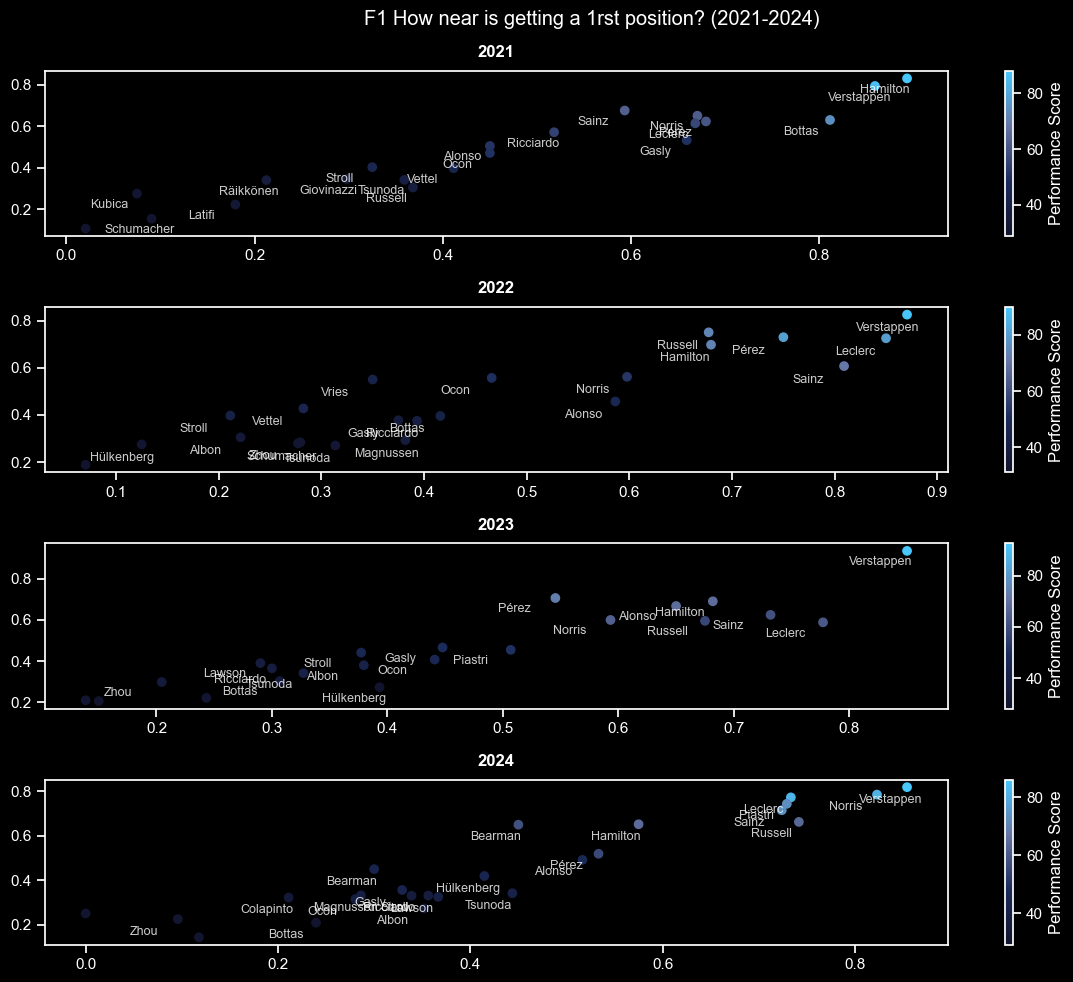

In [ ]:
F1_colors_2 = ['#12142D', '#1B2B5A', '#6674A3', '#47C7FC']

plt.figure(figsize=(12, 10))
plt.suptitle(f'F1 How near is getting a 1rst position? ({year_start}-{max_year})')
cmap_palette = mcolors.LinearSegmentedColormap.from_list('f1_color', F1_colors_2)

idx = 1
for year in range(year_start, max_year + 1):
    
    filter_year_metrics = final_metrics[final_metrics["year"] == year]
    filter_year_metrics['norm_fpos'] = 1 - (filter_year_metrics["avg_final_position"] / 20)
    filter_year_metrics['norm_qual'] = 1 - (filter_year_metrics["avg_qualifying"] / 20)

    plt.subplot(hbox_subplots_year*2, 1, idx)
    s = plt.scatter(filter_year_metrics['norm_qual'], filter_year_metrics['norm_fpos'], c=filter_year_metrics['performance_idx'], cmap=cmap_palette)
   
    plt.title(f'{year}', fontweight='bold', pad=10)
    
    for _, row in filter_year_metrics.iterrows():
        plt.annotate(row['driver_name'].split()[-1], 
                    (row['norm_qual'] - 0.05, row['norm_fpos'] - 0.07),
                    fontsize=9, alpha=0.8)
    plt.colorbar(s, label='Performance Score')
    plt.grid(False)
    plt.tight_layout()

    idx += 1

plt.show()
    

##

## Análisis Descriptivo 

### Progresión de puntos de los pilotos

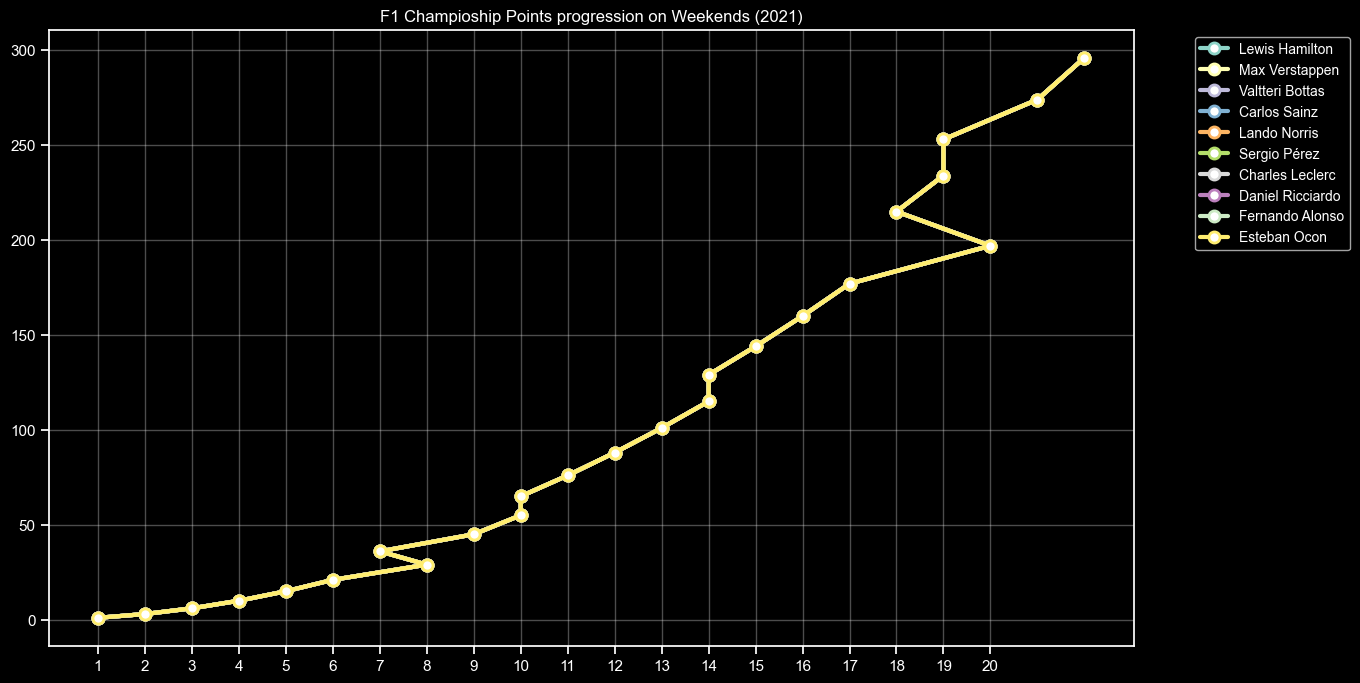

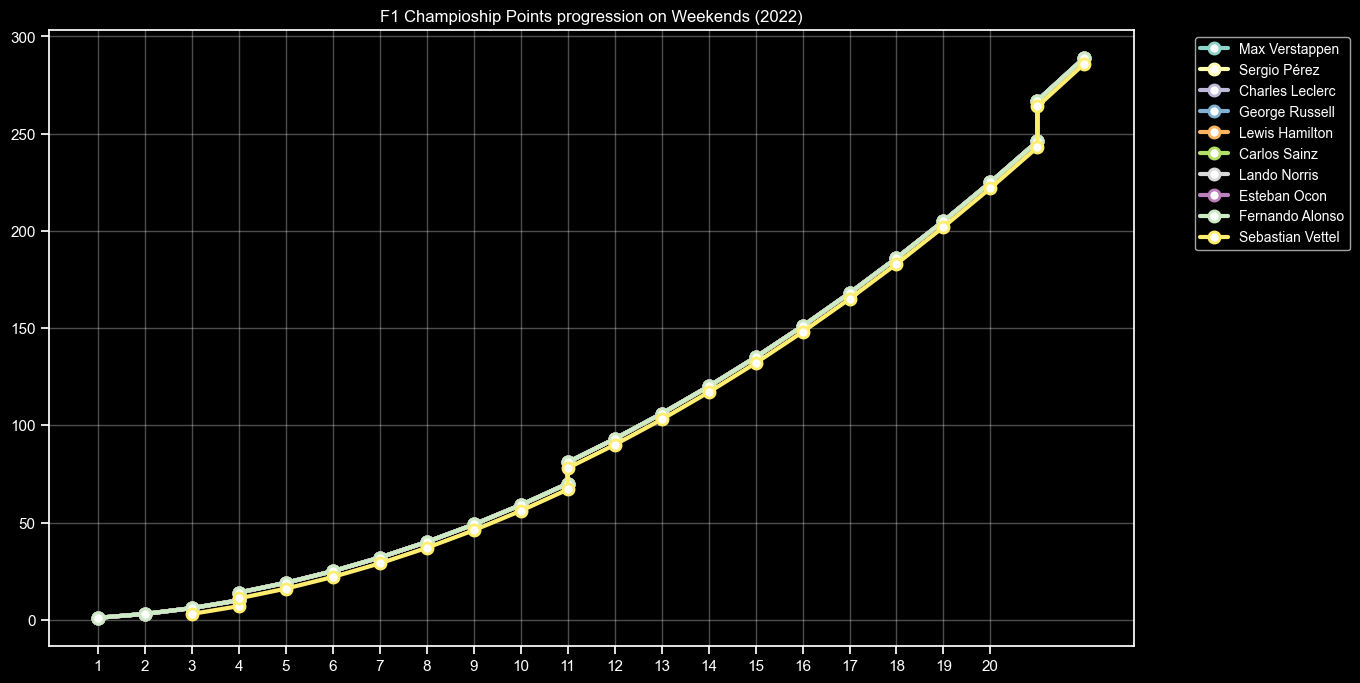

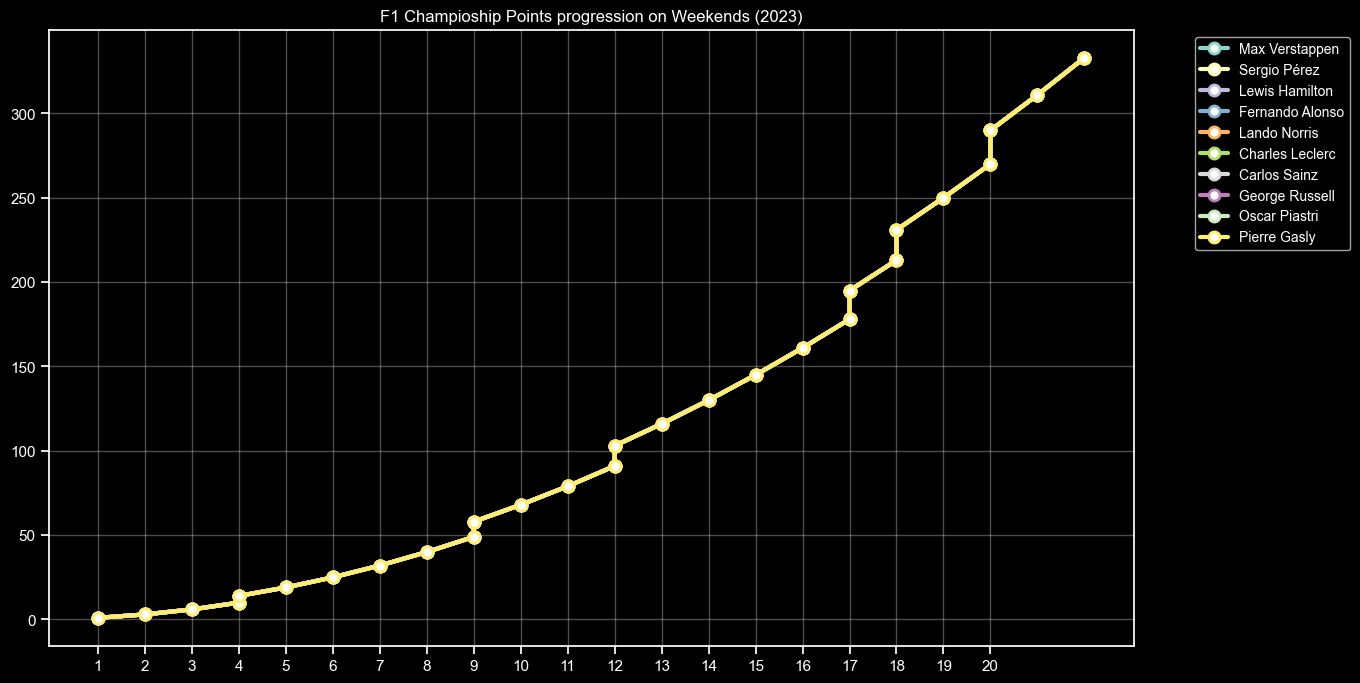

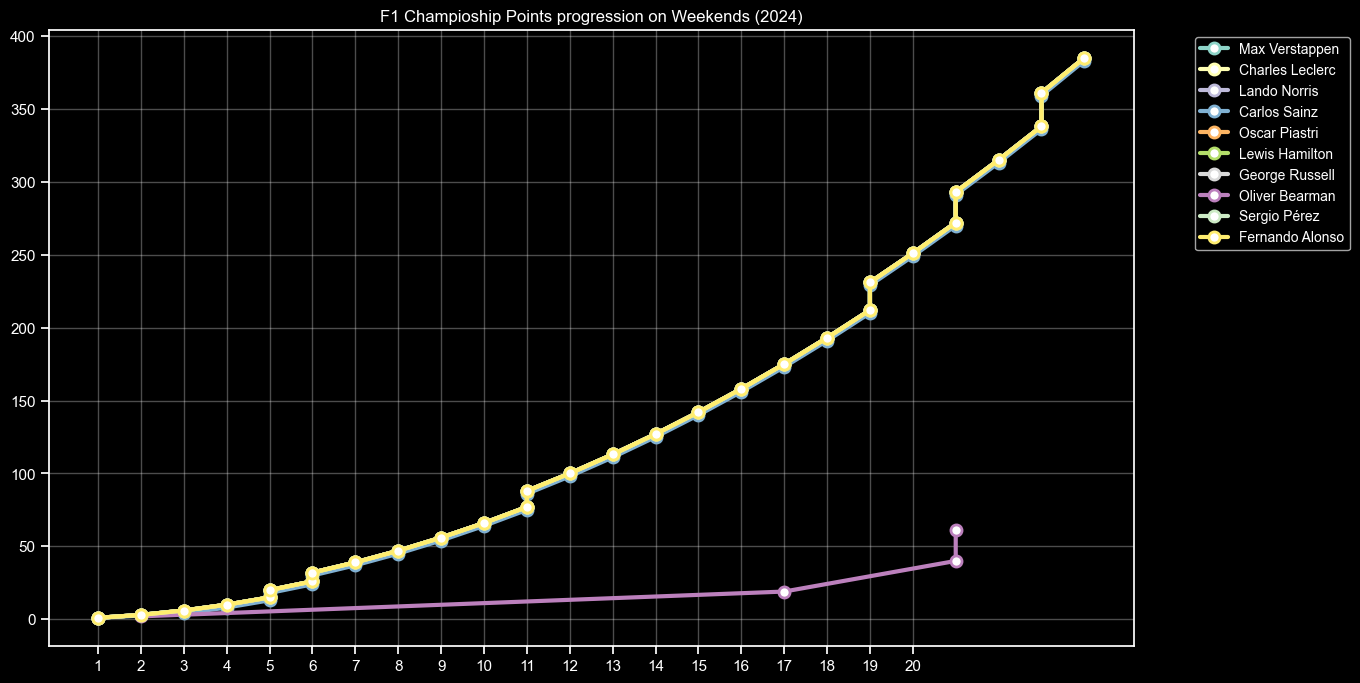

In [ ]:
for year in range(year_start, max_year + 1):
    filter_year = f1_EDA[f1_EDA["year"] == year]
    filter_year_metrics = final_metrics[final_metrics["year"] == year]
    top_drivers = filter_year_metrics["driver_name"].head(10)
        
    plt.figure(figsize=(14, 8))
    colors = plt.cm.Set3(np.linspace(0, 1, len(top_drivers)))

    for i, driver in enumerate(top_drivers):
        group_weekend = filter_year[filter_year['driver_name'] == driver]['WeekEnd']
        prev = 0
        progression_points = []
        for _, row in group_weekend.iterrows():
            prev += row["WeekEnd"]
            progression_points.append(prev)
        
        plt.plot(group_weekend, progression_points, 
                marker='o', linewidth=3, label=driver, markersize=8, color=colors[i],
                markerfacecolor='white', markeredgewidth=2)
        

    plt.title(f'F1 Champioship Points progression on Weekends ({year})')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
    plt.grid(True, alpha=0.3)
    plt.xticks(range(1, ))
    plt.show()
    